In [10]:
import numpy as np # <1.25 numpy needed
import matplotlib.pyplot as plt
import os 
import sys
from geometry_utils import (
    extract_combined_arc,
    mad_filter,
    segment_points,
    split_segments_by_line_deviation,
    smart_fit_segments,
    merge_collinear,
    detect_best_corner,
    detect_terminal_edges_from_fits,
    ransac_line,
    pca_fit,
    fit_segment,
    point_line_distance,
    pca_direction_angle,
    abs_line_angle_diff_deg,
    oriented_wall_dir,
    line_intersection,
    classify_segment_pair,
    shift_angle_deg,
    in_wrapped_arc,
)




# Choose experiment folder and scan file
expt_name = "pi_run_Aug19_1"   # full folder name
filename  = "scan_0045"      # file name without .npy

BASE_DIR = os.path.expanduser(
    "~/ros_ws/painting_robot_ws/src/test/corner_detect/data/lidar_scans"
)

# Build paths
EXPT_DIR = os.path.join(BASE_DIR, expt_name)
DATA_DIR = os.path.join(EXPT_DIR, "scans")
OUT_DIR  = os.path.join(EXPT_DIR, "outputs")

# Ensure directories exist
if not os.path.exists(DATA_DIR):
    raise FileNotFoundError(f"'scans' directory not found in {EXPT_DIR}")
os.makedirs(OUT_DIR, exist_ok=True)

# Load the chosen scan file
data_path = os.path.join(DATA_DIR, filename + ".npy")
if not os.path.exists(data_path):
    raise FileNotFoundError(f"Scan file not found: {data_path}")

print("Loading:", data_path)



data = np.load(data_path, allow_pickle=True).item()

# Now you can use `data`, and OUT_DIR for saving results

LIDAR_YAW_OFFSET = -np.pi   # RPLidar C1 raw-zero points behind arrow
ranges      = np.array(data['ranges'], dtype=np.float32)
valid = np.isfinite(ranges) & (ranges > 0.15) & (ranges < 15.0)


r = ranges[valid]          # <-- missing
angle_min   = data['angle_min']
angle_inc   = data['angle_increment']
angles      = angle_min + np.arange(len(ranges)) * angle_inc

angles_full = (angle_min + np.arange(len(ranges)) * angle_inc
                       + LIDAR_YAW_OFFSET) % (2 * np.pi)

# rebuild cartesian with the offset applied


a = angles_full[valid]
x = r * np.cos(a)
y = r * np.sin(a)
points = np.column_stack([x, y])


print(f"Total beams     : {len(ranges)}")
print(f"Angle min       : {np.degrees(angle_min):.1f}°")
print(f"Angle max       : {np.degrees(angles[-1]):.1f}°")
print(f"Angle increment : {np.degrees(angle_inc):.3f}°")
print(f"Range min (raw) : {np.nanmin(ranges):.3f} m")
print(f"Range max (raw) : {np.nanmax(ranges):.3f} m")
print(f"Inf/NaN count   : {np.sum(~np.isfinite(ranges))}")
print(f"num beams : {len(ranges)}")

Loading: /home/raiv/ros_ws/painting_robot_ws/src/test/corner_detect/data/lidar_scans/pi_run_Aug19_1/scans/scan_0045.npy
Total beams     : 720
Angle min       : -179.0°
Angle max       : 180.0°
Angle increment : 0.499°
Range min (raw) : 0.068 m
Range max (raw) : inf m
Inf/NaN count   : 90
num beams : 720


In [11]:

# angles_full = angle_min + np.arange(len(ranges)) * angle_inc




arc_r, arc_a, arc_xy = extract_combined_arc(ranges, angles_full)

segments = segment_points(arc_r, arc_a, arc_xy, threshold=0.15)

print(f"Arc points after clip: {len(arc_r)}")
print(f"Angle range: {arc_a[0]:.1f}° → {arc_a[-1]:.1f}°")



segments = split_segments_by_line_deviation(
    segments,
    deviation_threshold=0.05,
    min_points=8,
    min_angle_change_deg=12.0,
    debug=True,
)

segments = [
    seg for seg in segments
    if np.median(seg[0]) < 3.0
]  

    
for k, seg in enumerate(segments):
    seg_r, seg_a, seg_xy = seg

    print(
        k,
        "n=", len(seg_xy),
        "angle=", f"{seg_a[0]:.1f}->{seg_a[-1]:.1f}",
        "start=", seg_xy[0],
        "end=", seg_xy[-1],
    )



Arc points after clip: 233
Angle range: 226.7° → 29.5°

Checking segment 0: n=10 angle=226.7->234.2

Checking segment 1: n=9 angle=261.1->265.6

Checking segment 2: n=139 angle=268.1->337.0
SPLIT CANDIDATE: start=0, i=131, split_idx=124, angle=330.0, max_dev=0.1144, angle_change=88.1, left_n=124, right_n=8
  accepted

Checking segment 3: n=48 angle=339.5->4.0

Checking segment 4: n=15 angle=13.5->20.5

Checking segment 5: n=8 angle=26.0->29.5
0 n= 10 angle= 226.7->234.2 start= [-0.81822653 -0.86784668] end= [-0.62423072 -0.8647301 ]
1 n= 9 angle= 261.1->265.6 start= [-0.02665239 -0.17093463] end= [-0.01407272 -0.18421325]
2 n= 124 angle= 268.1->329.5 start= [-0.02868177 -0.87753142] end= [ 1.52036107 -0.89404481]
3 n= 15 angle= 330.0->337.0 start= [ 1.56664873 -0.90298374] end= [ 1.59745443 -0.67702613]
4 n= 48 angle= 339.5->4.0 start= [ 1.18089494 -0.44084835] end= [1.2010732  0.08389968]
5 n= 15 angle= 13.5->20.5 start= [2.46756803 0.59161961] end= [2.04511689 0.76353538]
6 n= 8 angl

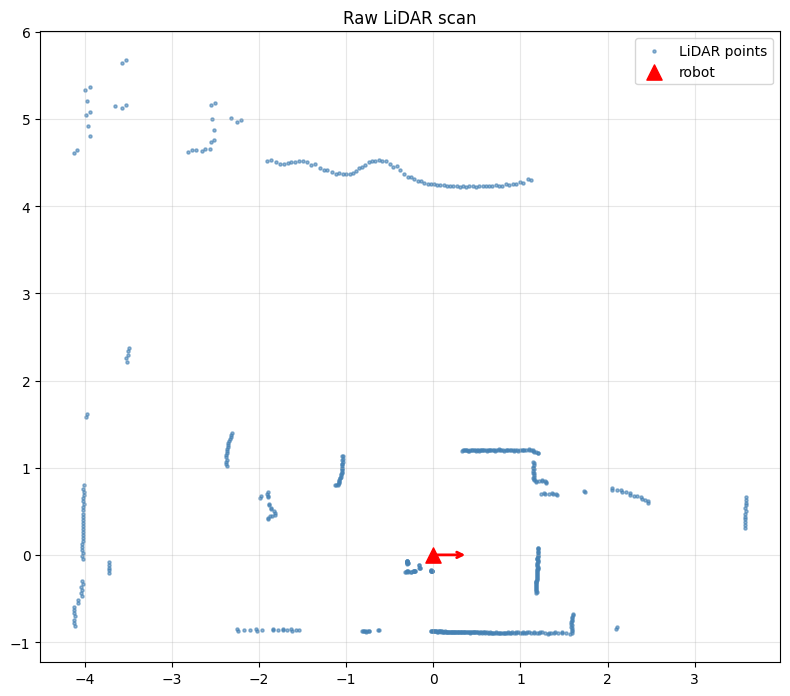

In [12]:

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(x, y, s=5, c='steelblue', alpha=0.6, label='LiDAR points')

# Robot marker at origin
ax.scatter(0, 0, c='red', s=120, marker='^', zorder=5, label='robot')
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Raw LiDAR scan")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, f"scan_{expt_name}.png"),
            dpi=150, bbox_inches='tight')
plt.show()

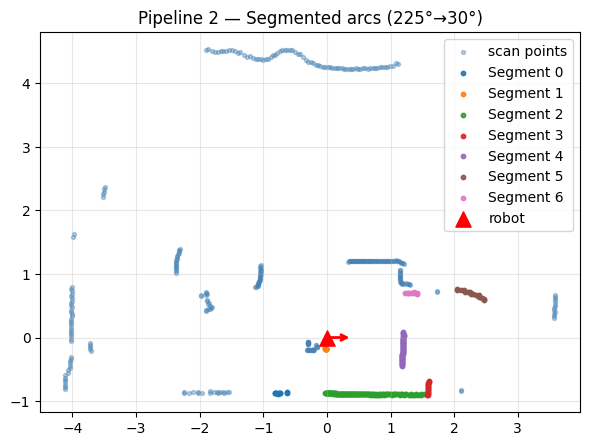

In [13]:
# ── Plot Full Scan + Segments ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Plot each segmented arc in a different color
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Robot marker (triangle pointing forward)
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)  # 0° beam direction
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Centered view around robot
# ax.set_xlim(-1.5, 2.5)
# ax.set_ylim(-1, 1.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title(f"Pipeline 2 — Segmented arcs (225°→30°)")
plt.tight_layout()
plt.show()


In [14]:
fits = smart_fit_segments(segments, min_points=8)
fits = merge_collinear(fits)

terminal_edges = detect_terminal_edges_from_fits(
    fits,
    ranges_raw=ranges,
    angles_full_rad=angles_full,
    max_range_interest=2.0,
    lookahead_beams=12,
    min_far_ratio=0.40,
    debug=True,
)



Terminal check fit 0: edge_angle=234.2, edge_pt=(-0.624,-0.865), far_ratio=0.58, ahead_ranges=[ inf  inf  inf  inf  inf  inf  inf 0.07 0.07 0.07 0.07 0.07]
Terminal check fit 1: edge_angle=265.6, edge_pt=(-0.014,-0.184), far_ratio=0.33, ahead_ranges=[ inf  inf  inf  inf 0.88 0.88 0.88 0.88 0.88 0.88 0.88 0.88]
Terminal check fit 2: edge_angle=329.5, edge_pt=(1.520,-0.894), far_ratio=0.00, ahead_ranges=[1.81 1.83 1.81 1.81 1.8  1.79 1.79 1.77 1.76 1.76 1.76 1.75]
Terminal check fit 3: edge_angle=337.0, edge_pt=(1.597,-0.677), far_ratio=0.33, ahead_ranges=[ inf 2.26 2.26  inf 1.26 1.26 1.25 1.24 1.24 1.24 1.23 1.23]
  Terminal check fit 4: skipped — edge near arc boundary (4.0°)
Terminal check fit 5: edge_angle=20.5, edge_pt=(2.045,0.764), far_ratio=0.67, ahead_ranges=[ inf  inf  inf 1.88 1.88  inf  inf  inf  inf  inf 1.58 1.58]
Terminal check fit 6: edge_angle=29.5, edge_pt=(1.231,0.696), far_ratio=0.42, ahead_ranges=[ inf  inf  inf  inf  inf 1.54 1.54 1.54 1.51 1.51 1.48 1.45]


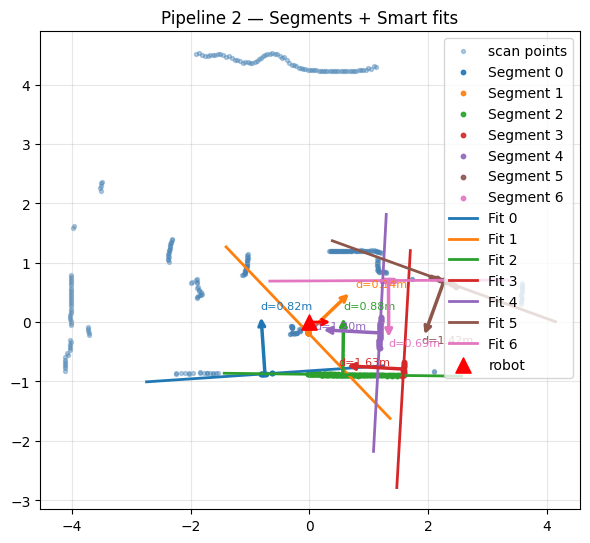

In [15]:
# ── Plot Full Scan + Segments + Smart Fits ────────────────────────────────
fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points (within 5 m)
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.4, label='scan points')

# Plot each segment in a different color
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(sxy[:, 0], sxy[:, 1], s=10,
               color=colors[i % len(colors)], alpha=0.9, label=f'Segment {i}')

# Overlay fitted lines from smart_fit_segments
for j, (f, sxy) in enumerate(fits):
    n, d, c = f['normal'], f['distance'], f['centroid']

    # line direction = perpendicular to normal
    wall_dir = np.array([-n[1], n[0]])

    # extend line through centroid
    p1 = c + wall_dir * 2.0
    p2 = c - wall_dir * 2.0
    ax.plot([p1[0], p2[0]], [p1[1], p2[1]],
            color=colors[j % len(colors)], lw=2, label=f'Fit {j}')

    # draw normal arrow from centroid toward robot
    ax.annotate('', xy=(c[0] + n[0], c[1] + n[1]), xytext=(c[0], c[1]),
                arrowprops=dict(arrowstyle='->', color=colors[j % len(colors)], lw=2.5))

    # label with distance
    ax.text(c[0] + n[0]*1.1, c[1] + n[1]*1.1,
            f'd={d:.2f}m', color=colors[j % len(colors)], fontsize=8)

# Robot marker (triangle pointing forward)
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)  # 0° beam direction
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=5, label='robot')

# Heading arrow
ax.annotate('', xy=(0.4, 0), xytext=(0, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2))

# Centered view around robot
# ax.set_xlim(-1.5, 2.5)
# ax.set_ylim(-1, 1.5)

ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title("Pipeline 2 — Segments + Smart fits")
plt.tight_layout()
plt.show()


In [16]:
result = detect_best_corner(fits)

# --- Match env_monitoring WALL_FOLLOW event selection ---

EXT_ARC_MIN = 270.0
EXT_ARC_MAX = 310.0
EXT_MAX_RANGE = 1.2
EXT_MIN_FRONT_X = 0.05

# Build events exactly like node
events = []

if result is not None:
    events.append({
        "type": result["type"],
        "point": result["vertex"],
        "radian_diff": result["radian_diff"],
        "angle_deg": result["angle_deg"],
        "turn_dir": "CCW" if result["radian_diff"] > 0 else "CW",
        "source": "line_intersection",
    })

for e in terminal_edges:
    events.append({
        "type": "EXTERNAL_EDGE",
        "point": e["point"],
        "radian_diff": -np.pi / 2,
        "angle_deg": 90.0,
        "turn_dir": "CW",
        "source": "terminal_dropout",
        "seg_idx": e["seg_idx"],
        "far_ratio": e["far_ratio"],
    })

def event_sort_key(ev):
    p = ev["point"]
    theta_deg = np.degrees(np.arctan2(float(p[1]), float(p[0]))) % 360.0
    return (theta_deg - 270.0) % 360.0

events.sort(key=event_sort_key)


# ── Env-style filtering + closest accepted event selection ────────────────

EXT_ARC_MIN = 270.0
EXT_ARC_MAX = 310.0
EXT_MAX_RANGE = 1.2
EXT_MIN_FRONT_X = 0.05

INT_MAX_FRONT_DIST = 0.6   # set same as int_corner_approach_dist
front_dist = 0.55          # replace with your computed front_dist if available

for ev in events:
    ev["accepted"] = False
    ev["rejected"] = False

for ev in events:
    p = ev["point"]
    vx, vy = float(p[0]), float(p[1])
    bearing = np.degrees(np.arctan2(vy, vx)) % 360.0
    vrange = np.hypot(vx, vy)

    if ev["type"] == "EXTERNAL_EDGE":
        ok = (
            EXT_ARC_MIN <= bearing <= EXT_ARC_MAX
            and vx > EXT_MIN_FRONT_X
            and vrange <= EXT_MAX_RANGE
        )

    elif ev["type"] == "INTERNAL":
        ok = (
            front_dist > 0.0
            and front_dist <= INT_MAX_FRONT_DIST
        )

    else:
        ok = False

    ev["accepted"] = bool(ok)
    ev["rejected"] = not bool(ok)

accepted_events = [e for e in events if e["accepted"]]
rejected_events = [e for e in events if e["rejected"]]

# Choose closest accepted event
accepted_event = None
if accepted_events:
    accepted_events.sort(key=lambda e: np.linalg.norm(e["point"]))
    accepted_event = accepted_events[0]

print("Accepted events:", len(accepted_events))
for ev in accepted_events:
    p = ev["point"]
    d = np.linalg.norm(p)
    print(
        f"  {ev['type']} source={ev['source']} "
        f"pt=({p[0]:.3f},{p[1]:.3f}) d={d:.2f}"
    )

print("Selected:")
if accepted_event is not None:
    p = accepted_event["point"]
    print(
        f"  {accepted_event['type']} source={accepted_event['source']} "
        f"pt=({p[0]:.3f},{p[1]:.3f})"
    )
else:
    print("  None")

print("Rejected events:", len(rejected_events))
for ev in rejected_events:
    p = ev["point"]
    vx, vy = float(p[0]), float(p[1])
    d = np.linalg.norm(p)
    bearing = np.degrees(np.arctan2(vy, vx)) % 360.0

    reasons = []

    if ev["type"] == "EXTERNAL_EDGE":
        if not (EXT_ARC_MIN <= bearing <= EXT_ARC_MAX):
            reasons.append("arc")
        if not (vx > EXT_MIN_FRONT_X):
            reasons.append("vx")
        if not (d <= EXT_MAX_RANGE):
            reasons.append("range")

    elif ev["type"] == "INTERNAL":
        if not (front_dist > 0.0):
            reasons.append("front_invalid")
        if not (front_dist <= INT_MAX_FRONT_DIST):
            reasons.append("front_far")

    print(
        f"  {ev['type']} source={ev['source']} "
        f"pt=({vx:.3f},{vy:.3f}) "
        f"d={d:.2f} bearing={bearing:.1f}° "
        f"reason={','.join(reasons) if reasons else 'unknown'}"
    )    

Accepted events: 1
  INTERNAL source=line_intersection pt=(1.583,-0.900) d=1.82
Selected:
  INTERNAL source=line_intersection pt=(1.583,-0.900)
Rejected events: 3
  EXTERNAL_EDGE source=terminal_dropout pt=(2.045,0.764) d=2.18 bearing=20.5° reason=arc,range
  EXTERNAL_EDGE source=terminal_dropout pt=(1.231,0.696) d=1.41 bearing=29.5° reason=arc,range
  EXTERNAL_EDGE source=terminal_dropout pt=(-0.624,-0.865) d=1.07 bearing=234.2° reason=arc,vx


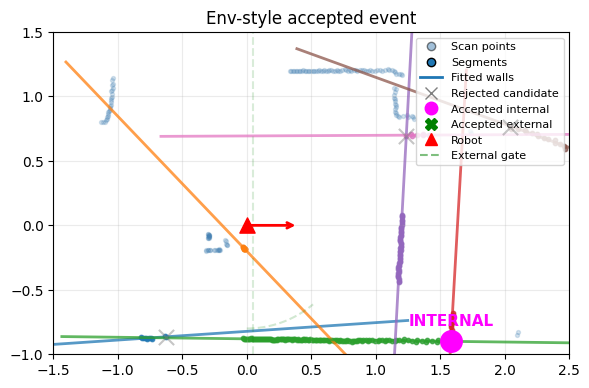

In [17]:
from matplotlib.lines import Line2D

# ── Clean plot: accepted event obvious, rejected candidates grey ──────────

fig, ax = plt.subplots(figsize=(6, 6))

# Full scan points
mask = r < 5.0
ax.scatter(x[mask], y[mask], s=8, c='steelblue', alpha=0.22)

# Segments
colors = plt.cm.tab10.colors
for i, (_, _, sxy) in enumerate(segments):
    ax.scatter(
        sxy[:, 0], sxy[:, 1],
        s=10,
        color=colors[i % len(colors)],
        alpha=0.7
    )

# Fits
for j, (f, sxy) in enumerate(fits):
    if f is None:
        continue

    n = f['normal']
    c = f['centroid']
    wall_dir = np.array([-n[1], n[0]])
    wall_dir /= np.linalg.norm(wall_dir) + 1e-9

    p1 = c + wall_dir * 2.0
    p2 = c - wall_dir * 2.0

    ax.plot(
        [p1[0], p2[0]],
        [p1[1], p2[1]],
        color=colors[j % len(colors)],
        lw=2,
        alpha=0.75
    )

# Rejected candidates: greyed out
for e in rejected_events:
    px, py = e["point"]
    marker = 'x' if e["type"] == "EXTERNAL_EDGE" else 'o'
    ax.scatter(
        px, py,
        c='gray',
        s=120,
        marker=marker,
        alpha=0.45,
        zorder=6
    )

# Accepted event: strong
for e in accepted_events:
    px, py = e["point"]

    if e["type"] == "EXTERNAL_EDGE":
        ax.scatter(px, py, c='green', s=240, marker='X', zorder=10)
        ax.text(
            px, py + 0.12,
            "EXTERNAL",
            color='green',
            fontsize=11,
            ha='center',
            fontweight='bold'
        )

    elif e["type"] == "INTERNAL":
        ax.scatter(px, py, c='magenta', s=240, marker='o', zorder=10)
        ax.text(
            px, py + 0.12,
            "INTERNAL",
            color='magenta',
            fontsize=11,
            ha='center',
            fontweight='bold'
        )

# Robot marker and heading
robot_marker = plt.matplotlib.markers.MarkerStyle('^')
robot_marker._transform.rotate_deg(0)
ax.scatter(0, 0, c='red', s=120, marker=robot_marker, zorder=12)

ax.annotate(
    '',
    xy=(0.4, 0),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle='->', color='red', lw=2)
)

# External gate visual
arc_angles = np.radians(np.linspace(EXT_ARC_MIN, EXT_ARC_MAX, 40))
ax.plot(
    0.8 * np.cos(arc_angles),
    0.8 * np.sin(arc_angles),
    'g--',
    alpha=0.18
)

ax.axvline(EXT_MIN_FRONT_X, color='green', linestyle='--', alpha=0.15)

# Simple custom legend
legend_items = [
    Line2D([0], [0], marker='o', color='none',
           markerfacecolor='steelblue', markersize=6, alpha=0.5,
           label='Scan points'),

    Line2D([0], [0], marker='o', color='none',
           markerfacecolor='tab:blue', markersize=6,
           label='Segments'),

    Line2D([0], [0], color='tab:blue', lw=2,
           label='Fitted walls'),

    Line2D([0], [0], marker='x', color='gray',
           markersize=8, linestyle='none',
           label='Rejected candidate'),

    Line2D([0], [0], marker='o', color='magenta',
           markersize=9, linestyle='none',
           label='Accepted internal'),

    Line2D([0], [0], marker='X', color='green',
           markersize=9, linestyle='none',
           label='Accepted external'),

    Line2D([0], [0], marker='^', color='red',
           markersize=9, linestyle='none',
           label='Robot'),

    Line2D([0], [0], color='green', lw=1.5,
           linestyle='--', alpha=0.5,
           label='External gate'),
]

ax.legend(handles=legend_items, loc='upper right', fontsize=8)

ax.set_xlim(-1.5, 2.5)
ax.set_ylim(-1.0, 1.5)
ax.set_aspect('equal')
ax.grid(True, alpha=0.25)
ax.set_title("Env-style accepted event")
plt.tight_layout()
plt.show()